# 007 Batch Normalization：题目要求

**需要完成：** 实现训练/推理前向和反向；检查均值方差、滑动统计和梯度；比较普通反向与简化反向；训练有/无 BN 的深层网络并完成初始化尺度扫描。

**实验范围与验收：** 比较收敛、泛化和初始化敏感性，不预设 BN 必然提高所有配置的验证准确率。

**阅读顺序：** 先阅读原题和代码块前的中文解析，再检查实际输出与问题记录；若本题包含方法二，它紧随对应方法一，使用独立状态。方法一不得依赖方法二才能运行。

**课程参考：** [CS231n 课程资料](https://cs231n.github.io/)。本题的实现、检查和实验结果按下文顺序记录。

## 读代码前先看模型：批量归一化

训练时同一列的 N 个样本共同决定统计量，因此一个样本会影响同列其他样本的梯度。推理时使用训练期间积累的滑动均值与方差。

![批量归一化的数据流](../assets/model_flow/007_BatchNormalization.svg)

**从定义推到实现。**

$$
\hat x=(x-\mu)/\sqrt{v+\epsilon},\quad y=\gamma\hat x+\beta
$$

设 g=上游梯度×γ。链式求导可化简为 dx=(g−mean(g)−x̂·mean(g·x̂))/√(v+ε)。后两项分别来自均值与方差也依赖 x。γ 的导数为 Σ(dy·x̂)，β 的导数为 Σdy，求和都沿样本轴。

**库在这里解决什么问题？** NumPy 的 mean/var 指定 axis=0，只消去样本维。bn_param 保存模式及滑动统计；有限差分检查既要看输入，也要看 γ、β。

| 本题导入的模块 | 在这份实验中的用途 |
|---|---|
| `__future__` | 声明历史 Python 兼容语义。 |
| `cs231n.classifiers.fc_net` | 加载当前作业的本地实现。模型代码负责计算预测或损失，notebook 用真实输入检查和训练。 |
| `cs231n.data_utils` | 处理该作业的数据、特征或显示输入，使主实验能直接使用约定的数组格式。 |
| `cs231n.gradient_check` | 用中心差分近似导数，独立核对手写反向传播。 |
| `cs231n.solver` | 负责批次抽样、训练循环和参数更新，使模型的 loss 方法只处理一次计算。 |
| `matplotlib.pyplot` | 把像素、损失或准确率转换为可读图像，绘图单元只读取已有结果。 |
| `numpy` | 把一批样本作为数组处理。矩阵乘法合并样本计算，广播让偏置或均值沿样本轴复用。 |
| `os` | 读取运行环境或处理路径，连接实验代码和本机文件系统。 |
| `pathlib` | 构造数据与结果的文件路径，使当前作业从约定目录读取资源。 |
| `random` | 控制 Python 自己的随机抽样，例如图像平移。它与 NumPy、PyTorch 的随机状态分别管理。 |
| `study_runtime` | 解析共享数据路径、读取本机资源或保存本题结果，避免各题重复创建数据副本。 |
| `sys` | 设置本作业的模块搜索路径，使同名 cs231n 包来自当前 assignment。 |
| `threadpoolctl` | 限制数值库的并行线程，避免小矩阵运算把更多时间花在线程调度上。 |
| `time` | 测量代码开始与结束的实际时间，在相同输入上比较实现成本。 |

**用一个小例子检查理解。** 某特征在两个样本上为 [1,3]，均值 2、方差 1。忽略很小的 ε，标准化后为 [−1,1]。改变第一个输入时均值也变，因此第二个样本的输出同样会改变。

## 读论文图：BN 对训练过程产生了什么影响？

![BN 论文图 1](../assets/paper_figures/BN_Fig1.png)

图源：Ioffe 与 Szegedy，*Batch Normalization*，ICML 2015，图 1，PDF 第 6 页。[查看论文原页](https://proceedings.mlr.press/v37/ioffe15.pdf#page=6)

先看 (a)。横轴是训练步数，纵轴是测试准确率，对应作者的 MNIST 实验。再看 (b)、(c)。曲线追踪一个选定激活的不同分位数，它们反映训练过程中该激活的分布变化，不能当作三个类别或三条损失曲线。

沿代码读一次：batchnorm_forward 先按列求当前批次的均值和方差，再经 γ、β 缩放和平移，输出给 ReLU。当前批次统计量参与本次计算，同时更新推理用的滑动统计。反向时，改变任一样本也会改变同列的均值、方差，因此只写 dy·γ/√(v+ε) 会漏掉两条间接路径。

这张图展示论文设置下的优化轨迹。本题自己的效果应结合相同数据划分下有无 BN 的训练曲线，以及不同初始化尺度的结果判断。

# 批量归一化
使深层网络更容易训练的一种方法是使用更复杂的优化过程，如SGD+momentum、RMSProp或Adam。另一个策略是改变网络的结构，使其更容易训练。这方面的一个想法是批量标准化，这是最近由[3]提出的。

这个想法相对简单。当输入数据由零均值和单位方差的不相关特征组成时，机器学习方法的效果往往更好。在训练神经网络时，我们可以先对数据进行预处理，然后再将其输入网络，以显式地去关联其特征;这将确保网络的第一层能够看到遵循良好分布的数据。然而，即使我们对输入数据进行预处理，网络较深层的活动也可能不再具有去相关性，也不再具有零均值或单位方差，因为它们是从网络较早的层中输出的。更糟糕的是，在训练过程中，网络每一层的特征分布会随着每一层权重的更新而改变。

[3]的作者假设，深层神经网络内部特征分布的变化可能使深层神经网络的训练更加困难。为了克服这个问题，[3]建议将批处理规范化层插入到网络中。在训练时，批处理归一化层使用小批数据估计每个特征的均值和标准差。这些估计的平均值和标准偏差然后用于中心和标准化的特征的小批量。在训练期间，这些平均值和标准偏差的运行平均值被保持，在测试时，这些运行平均值被用来集中和标准化特征。

这种归一化策略可能会降低网络的表示能力，因为有时某些层的特征不是零均值或单位方差的，这可能是最优的。为此，批处理规范化层包括每个特征维的可学习的移位和缩放参数。

[3] 谢尔盖·欧夫和克里斯蒂安·西格迪,"批量正常化:通过减少 加速深网训练
内部共变移",ICML 2015.

**本段解析**

固定 NumPy 与 Python 随机种子为 231，读取共享数据配置，并限制 BLAS 线程数量。这样既能运行验证初始化和抽样，也能避免小矩阵运算中线程调度开销；原始数据文件保持不变。

**第 1 块：顺着变量读**

本块实际导入：`os`、`sys`、`random`、`pathlib.Path`、`study_runtime.data_path`、`numpy`、`threadpoolctl.threadpool_limits`。各模块在本题中的职责见开头的库说明。

In [1]:
# 固定实验起点；读取共享数据路径；限制 BLAS 线程，避免多线程调度开销。
import os, sys, random
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from study_runtime import data_path
import numpy as np
from threadpoolctl import threadpool_limits
_blas_limit = threadpool_limits(limits=4)
np.random.seed(231)
random.seed(231)


**第 2 块｜准备 BN 算子**

导入 Batch Normalization 前后向、全连接网络及 Solver。BN 在训练模式使用当前批次统计量，推理模式使用滑动平均；两条路径都需要独立验证。

此处定义 `rel_error(x, y)`。函数体在调用时执行。

本块实际导入：`__future__.print_function`、`time`、`numpy`、`matplotlib.pyplot`、`cs231n.classifiers.fc_net.*`、`cs231n.data_utils.get_CIFAR10_data`、`cs231n.gradient_check.eval_numerical_gradient`、`cs231n.gradient_check.eval_numerical_gradient_array`、`cs231n.solver.Solver`。各模块在本题中的职责见开头的库说明。

本块产出的变量接着用于：`rel_error` → 第 6 块。

In [2]:
# 跟往常一样,有点陷害
from __future__ import print_function
import time
import numpy as np
import matplotlib.pyplot as plt
from cs231n.classifiers.fc_net import *
from cs231n.data_utils import get_CIFAR10_data
from cs231n.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from cs231n.solver import Solver

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # 设置地块的默认大小
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# 用于自动重新装入外部模块
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

def rel_error(x, y):
  """逐元素计算 |x−y| / max(1e−8, |x|+|y|)，返回其中最大值。分母很小时还应查看绝对误差。"""
  return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

**第 3 块｜读取实验划分**

读取课程 CIFAR-10 划分，打印数据形状。归一化实验中的子集仅从训练部分选取，验证数据保持固定。

本块产出的变量接着用于：`data` → 第 9 块。

In [3]:
# 装入(预处理的)CIFAR10数据.

data = get_CIFAR10_data()
for k, v in data.items():
  print('%s: ' % k, v.shape)

X_train:  (49000, 3, 32, 32)
y_train:  (49000,)
X_val:  (1000, 3, 32, 32)
y_val:  (1000,)
X_test:  (1000, 3, 32, 32)
y_test:  (1000,)


## 批量标准化：前向传递
在文件 `cs231n/layers.py`函数`batchnorm_forward`中实现批量标准化前向传递。完成之后，运行以下代码来测试您的实现。

**第 4 块｜检查训练批次统计**

给输入特征设置非零均值和非单位方差，执行训练模式 BN 并检查输出统计。先标准化为近似零均值单位方差，再使用 gamma 缩放、beta 平移；eps 防止方差为零时除零。



In [4]:
# 通过检查手段和差异检查训练时间
# 分批正常化之前和之后

# 模拟双层网络的前进通道
np.random.seed(231)
N, D1, D2, D3 = 200, 50, 60, 3
X = np.random.randn(N, D1)
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)
a = np.maximum(0, X.dot(W1)).dot(W2)

print('Before batch normalization:')
print('  means: ', a.mean(axis=0))
print('  stds: ', a.std(axis=0))

# 手段应接近于零和接近于一个
print('After batch normalization (gamma=1, beta=0)')
a_norm, _ = batchnorm_forward(a, np.ones(D3), np.zeros(D3), {'mode': 'train'})
print('  mean: ', a_norm.mean(axis=0))
print('  std: ', a_norm.std(axis=0))

# 现在意味着应该接近β 和stds接近γ
gamma = np.asarray([1.0, 2.0, 3.0])
beta = np.asarray([11.0, 12.0, 13.0])
a_norm, _ = batchnorm_forward(a, gamma, beta, {'mode': 'train'})
print('After batch normalization (nontrivial gamma, beta)')
print('  means: ', a_norm.mean(axis=0))
print('  stds: ', a_norm.std(axis=0))

Before batch normalization:
  means:  [ -2.3814598  -13.18038246   1.91780462]
  stds:  [27.18502186 34.21455511 37.68611762]
After batch normalization (gamma=1, beta=0)
  mean:  [ 3.55271368e-17  7.10542736e-17 -2.65065747e-17]
  std:  [0.99999999 1.         1.        ]
After batch normalization (nontrivial gamma, beta)
  means:  [11. 12. 13.]
  stds:  [0.99999999 1.99999999 2.99999999]


**第 5 块｜检查推理用的滑动统计**

多次训练模式前向更新 running_mean 和 running_var，随后切到 test 模式。新的输入只能使用已经积累的滑动统计，不得在测试批次上重新估计；均值方差接近目标而非必须精确相等。

本块产出的变量接着用于：`a` → 第 6 块。

In [5]:
# 通过运行训练时间来检查测试时间
# 转过多次热身,然后
# 检查测试时间后激活的手段和差异
# 前进通过。
np.random.seed(231)
N, D1, D2, D3 = 200, 50, 60, 3
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)

bn_param = {'mode': 'train'}
gamma = np.ones(D3)
beta = np.zeros(D3)
for t in range(50):
  X = np.random.randn(N, D1)
  a = np.maximum(0, X.dot(W1)).dot(W2)
  batchnorm_forward(a, gamma, beta, bn_param)
bn_param['mode'] = 'test'
X = np.random.randn(N, D1)
a = np.maximum(0, X.dot(W1)).dot(W2)
a_norm, _ = batchnorm_forward(a, gamma, beta, bn_param)

# 手段应该接近零, Stds 接近一个,但将会是
# 与训练时间相比,无声无息。
print('After batch normalization (test-time):')
print('  means: ', a_norm.mean(axis=0))
print('  stds: ', a_norm.std(axis=0))

After batch normalization (test-time):
  means:  [-0.03927354 -0.04349152 -0.10452688]
  stds:  [1.01531428 1.01238373 0.97819988]


## 批处理标准化:后向传递
现在在函数`batchnorm_backwards`中实现批处理规范化的后向遍历。
要获得向后传递，您应该写出批处理规范化的计算图，并通过每个中间节点进行支持。一些中间体可能有多个传出分支;确保在后向遍历中对这些分支的梯度求和。
一旦你完成了，运行下面的数字检查你的向后通过。

**第 6 块｜分别扰动输入与缩放平移参数**

对 x、gamma、beta 分别作数值梯度检查。x 的梯度必须考虑样本共同参与均值和方差的依赖，不能仅把 gamma/sqrt(var+eps) 当作全部导数。

前序输入：`a` 来自第 5 块，`rel_error` 来自第 2 块。

In [6]:
# 逐步检查批次向后通过
np.random.seed(231)
N, D = 4, 5
x = 5 * np.random.randn(N, D) + 12
gamma = np.random.randn(D)
beta = np.random.randn(D)
dout = np.random.randn(N, D)

bn_param = {'mode': 'train'}
fx = lambda x: batchnorm_forward(x, gamma, beta, bn_param)[0]
fg = lambda a: batchnorm_forward(x, a, beta, bn_param)[0]
fb = lambda b: batchnorm_forward(x, gamma, b, bn_param)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
da_num = eval_numerical_gradient_array(fg, gamma.copy(), dout)
db_num = eval_numerical_gradient_array(fb, beta.copy(), dout)

_, cache = batchnorm_forward(x, gamma, beta, bn_param)
dx, dgamma, dbeta = batchnorm_backward(dout, cache)
print('dx error: ', rel_error(dx_num, dx))
print('dgamma error: ', rel_error(da_num, dgamma))
print('dbeta error: ', rel_error(db_num, dbeta))

dx error:  1.7029241291468676e-09
dgamma error:  7.420414216247087e-13
dbeta error:  2.8795057655839487e-12


## 批处理标准化:可选向后(可选，+3分额外学分)
在课堂上，我们讨论了sigmoid向后传递的两种不同实现。一种策略是通过所有中间值写出由简单操作和支撑组成的计算图。另一种策略是在纸上计算出衍生品。对于sigmoid函数，可以通过在纸上简化梯度得到一个非常简单的后向遍历公式。
令人惊讶的是，如果您在纸上计算导数并进行简化，您还可以得到一个简单的表达式，用于批处理规范化的反向传递。这样做之后，在函数`batchnorm_backward_alt`中实现简化的批处理规范化后向传递，并通过运行以下代码比较这两个实现。您的两个实现应该计算几乎相同的结果，但是另一个实现应该更快一些。
注:这部分作业是完全可选的，但如果你能完成，我们将奖励3分的额外学分。

**第 7 块｜比较两条反向路径**

对同一 cache 和 dout 比较逐步链式反向与化简后的 batchnorm_backward_alt。检查 dx、dgamma、dbeta 一致后，再比较运行时间；原题已包含的简化反向不算本次新增方法二。

前序输入：`rel_error` 来自第 2 块。

In [7]:
np.random.seed(231)
N, D = 100, 500
x = 5 * np.random.randn(N, D) + 12
gamma = np.random.randn(D)
beta = np.random.randn(D)
dout = np.random.randn(N, D)

bn_param = {'mode': 'train'}
out, cache = batchnorm_forward(x, gamma, beta, bn_param)

t1 = time.perf_counter()
dx1, dgamma1, dbeta1 = batchnorm_backward(dout, cache)
t2 = time.perf_counter()
dx2, dgamma2, dbeta2 = batchnorm_backward_alt(dout, cache)
t3 = time.perf_counter()

print('dx difference: ', rel_error(dx1, dx2))
print('dgamma difference: ', rel_error(dgamma1, dgamma2))
print('dbeta difference: ', rel_error(dbeta1, dbeta2))
print('speedup: %.2fx' % ((t2 - t1) / (t3 - t2)))

dx difference:  1.0475263156312713e-10
dgamma difference:  0.0
dbeta difference:  0.0
speedup: 1.98x


## 全连接网络与批量标准化
现在您已经有了批处理规范化的工作实现，回到文件`cs2312n/classifier /fc_net.py`中的`FullyConnectedNet`。修改您的实现以添加批处理规范化。
具体来说，当构造函数中的`use_batchnorm `标记为`True`时，应该在每个ReLU非线性之前插入一个批处理规范化层。网络最后一层的输出不应该被规范化。完成之后，运行以下步骤来逐步检查实现。
提示:您可能会发现定义一个类似于文件`cs231n/layer_utils.py`中的附加帮助层很有用。如果您决定这样做，请在`cs231n/classifiers/fc_net.py`文件中执行。

**第 8 块｜检查 BN 接入整网后的梯度**

将 BN 接入多层网络，在不同正则强度下检查所有参数梯度，包括每个隐藏层新增的 gamma、beta。BN 位于 affine 与 ReLU 之间，测试同时检验模型连接顺序和缓存组织。

- `np.random.randint(C, size=(N,))`：从给定整数范围抽样，结果用作索引或离散标签。

前序输入：`rel_error` 来自第 2 块。

In [8]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

for reg in [0, 3.14]:
  print('Running check with reg = ', reg)
  model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                            reg=reg, weight_scale=5e-2, dtype=np.float64,
                            use_batchnorm=True)

  loss, grads = model.loss(X, y)
  print('Initial loss: ', loss)

  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
    print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))
  if reg == 0: print()

Running check with reg =  0
Initial loss:  2.2611955101340957
W1 relative error: 1.10e-04


W2 relative error: 2.85e-06
W3 relative error: 4.05e-10
b1 relative error: 2.78e-09
b2 relative error: 2.22e-08
b3 relative error: 1.01e-10
beta1 relative error: 7.33e-09
beta2 relative error: 1.89e-09
gamma1 relative error: 6.96e-09
gamma2 relative error: 1.96e-09

Running check with reg =  3.14
Initial loss:  6.996533220108303


W1 relative error: 1.98e-06


W2 relative error: 2.28e-06
W3 relative error: 1.11e-08
b1 relative error: 5.55e-09
b2 relative error: 2.22e-08
b3 relative error: 2.10e-10
beta1 relative error: 6.65e-09
beta2 relative error: 3.39e-09
gamma1 relative error: 6.27e-09
gamma2 relative error: 5.28e-09


## 深度网络的批量标准化
运行以下命令，在1000个训练示例的子集上训练一个六层网络，包括有和没有批处理规范化的示例。

**第 9 块｜训练有无 BN 的网络**

对 1000 张训练图分别训练使用和不使用 BN 的深层全连接网络，使用相同层宽与训练轮数。记录每组模型及优化器状态，比较收敛轨迹而不是只看最终训练损失。

前序输入：`data` 来自第 3 块。

本块产出的变量接着用于：`bn_solver` → 第 10 块，`solver` → 第 10 块。

In [9]:
np.random.seed(231)
# 尝试训练一个很深的网 与批量规范
hidden_dims = [100, 100, 100, 100, 100]

num_train = 1000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

weight_scale = 2e-2
bn_model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, use_batchnorm=True)
model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, use_batchnorm=False)

bn_solver = Solver(bn_model, small_data,
                num_epochs=10, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-3,
                },
                verbose=True, print_every=200)
bn_solver.train()

solver = Solver(model, small_data,
                num_epochs=10, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-3,
                },
                verbose=True, print_every=200)
solver.train()

(Iteration 1 / 200) loss: 2.340974
(Epoch 0 / 10) train acc: 0.107000; val_acc: 0.115000


(Epoch 1 / 10) train acc: 0.314000; val_acc: 0.266000


(Epoch 2 / 10) train acc: 0.385000; val_acc: 0.279000


(Epoch 3 / 10) train acc: 0.494000; val_acc: 0.308000


(Epoch 4 / 10) train acc: 0.531000; val_acc: 0.307000


(Epoch 5 / 10) train acc: 0.574000; val_acc: 0.313000


... (6 outputs left out)

(Epoch 4 / 10) train acc: 0.390000; val_acc: 0.310000
(Epoch 5 / 10) train acc: 0.434000; val_acc: 0.300000


(Epoch 6 / 10) train acc: 0.536000; val_acc: 0.346000
(Epoch 7 / 10) train acc: 0.530000; val_acc: 0.310000


(Epoch 8 / 10) train acc: 0.622000; val_acc: 0.342000
(Epoch 9 / 10) train acc: 0.654000; val_acc: 0.328000


(Epoch 10 / 10) train acc: 0.728000; val_acc: 0.335000


运行以下命令来可视化上面训练的两个网络的结果。您应该会发现，使用批处理规范化有助于网络更快地收敛。

**第 10 块｜比较两组训练轨迹**

把普通网络与 BN 网络的损失、训练准确率和验证准确率并排绘制。BN 可能改善优化稳定性，但验证收益仍取决于本次实验；训练更快不自动等于更好泛化。

前序输入：`solver` 来自第 9 块，`bn_solver` 来自第 9 块。

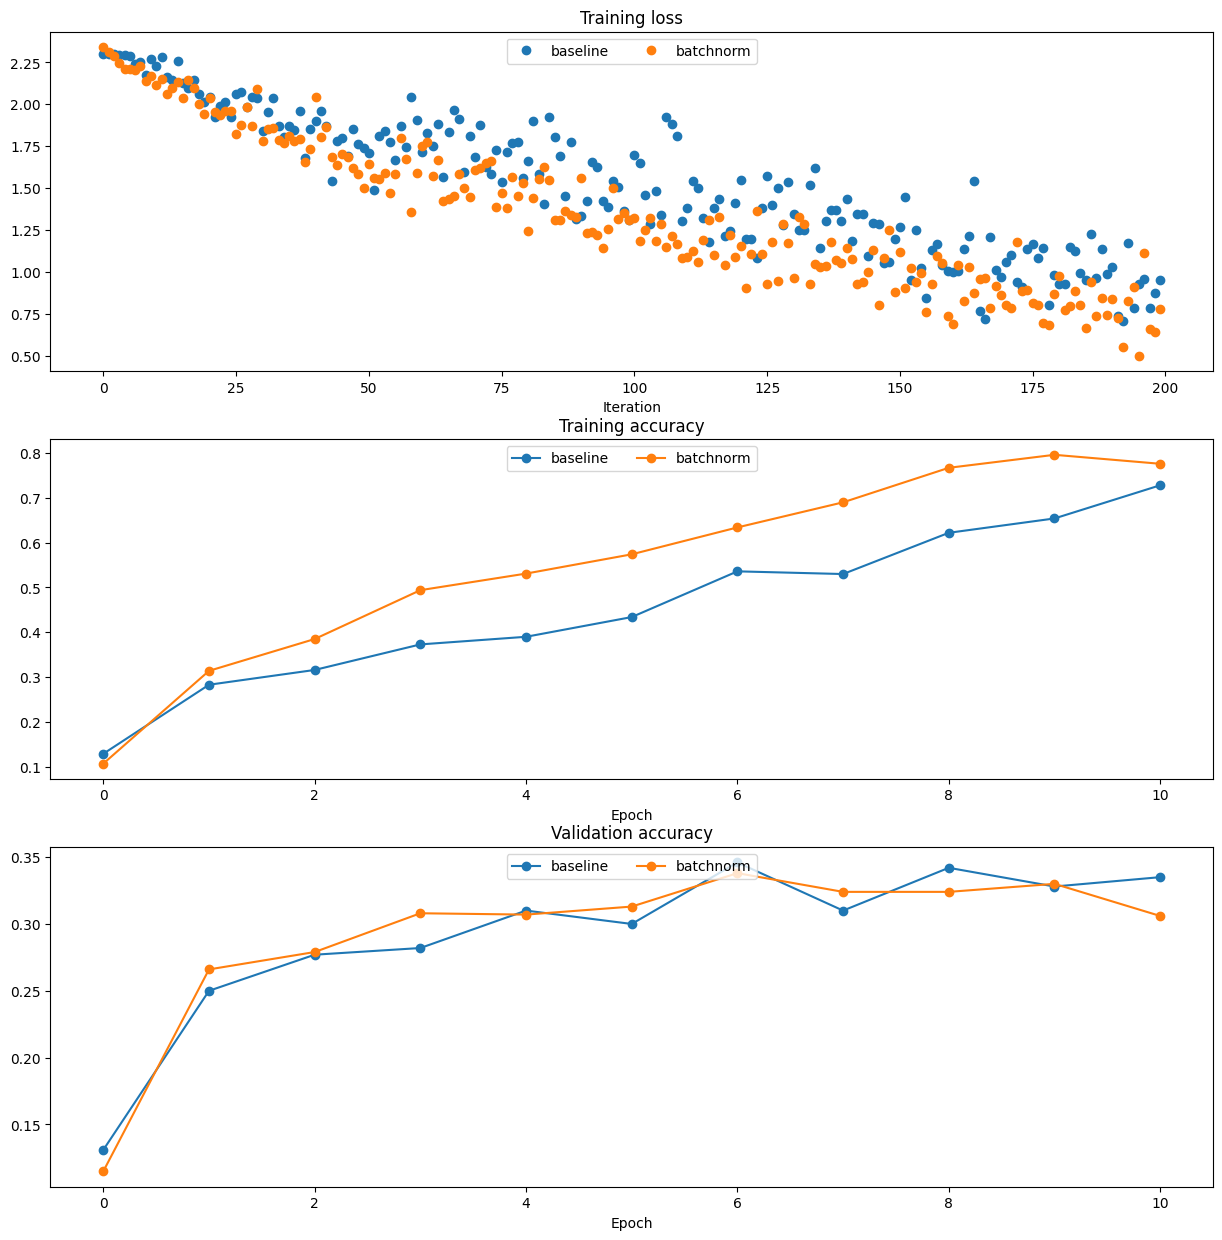

In [10]:
plt.subplot(3, 1, 1)
plt.title('Training loss')
plt.xlabel('Iteration')

plt.subplot(3, 1, 2)
plt.title('Training accuracy')
plt.xlabel('Epoch')

plt.subplot(3, 1, 3)
plt.title('Validation accuracy')
plt.xlabel('Epoch')

plt.subplot(3, 1, 1)
plt.plot(solver.loss_history, 'o', label='baseline')
plt.plot(bn_solver.loss_history, 'o', label='batchnorm')

plt.subplot(3, 1, 2)
plt.plot(solver.train_acc_history, '-o', label='baseline')
plt.plot(bn_solver.train_acc_history, '-o', label='batchnorm')

plt.subplot(3, 1, 3)
plt.plot(solver.val_acc_history, '-o', label='baseline')
plt.plot(bn_solver.val_acc_history, '-o', label='batchnorm')
  
for i in [1, 2, 3]:
  plt.subplot(3, 1, i)
  plt.legend(loc='upper center', ncol=4)
plt.gcf().set_size_inches(15, 15)
plt.show()

# 批处理规范化和初始化
现在，我们将进行一个小实验来研究批处理规范化和权值初始化之间的相互作用。
第一个单元将训练8层网络，使用不同规模的权重初始化进行批处理规范化和不进行批处理规范化。第二层将绘制训练精度、验证集精度、训练损失作为权重初始化量表的函数。

**第 11 块｜扫描初始化尺度**

在 20 个对数间隔的权重初始化尺度上分别训练有/无 BN 的八层网络，每个配置完成十轮。输入仍为同一训练子集，输出两组 Solver 字典，保存不同初始化条件下的真实轨迹。

前序输入：`data` 来自第 3 块。

本块产出的变量接着用于：`bn_solvers` → 第 12 块，`solvers` → 第 12 块，`weight_scales` → 第 12 块。

In [11]:
np.random.seed(231)
# 尝试训练一个很深的网 与批量规范
hidden_dims = [50, 50, 50, 50, 50, 50, 50]

num_train = 1000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

bn_solvers = {}
solvers = {}
weight_scales = np.logspace(-4, 0, num=20)
for i, weight_scale in enumerate(weight_scales):
  print('Running weight scale %d / %d' % (i + 1, len(weight_scales)))
  bn_model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, use_batchnorm=True)
  model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, use_batchnorm=False)

  bn_solver = Solver(bn_model, small_data,
                  num_epochs=10, batch_size=50,
                  update_rule='adam',
                  optim_config={
                    'learning_rate': 1e-3,
                  },
                  verbose=False, print_every=200)
  bn_solver.train()
  bn_solvers[weight_scale] = bn_solver

  solver = Solver(model, small_data,
                  num_epochs=10, batch_size=50,
                  update_rule='adam',
                  optim_config={
                    'learning_rate': 1e-3,
                  },
                  verbose=False, print_every=200)
  solver.train()
  solvers[weight_scale] = solver

Running weight scale 1 / 20


Running weight scale 2 / 20


Running weight scale 3 / 20


Running weight scale 4 / 20


Running weight scale 5 / 20


Running weight scale 6 / 20


... (10 outputs left out)

Running weight scale 17 / 20


Running weight scale 18 / 20


Running weight scale 19 / 20


Running weight scale 20 / 20


**第 12 块｜读取不同尺度的结果**

提取每组实验的最高训练/验证准确率及最后 100 步平均损失，随初始化尺度绘图。最高值是训练过程中的最佳值，并非所有模型最后一轮结果；极端尺度失败应保留，不能只报告成功区间。

前序输入：`weight_scales` 来自第 11 块，`solvers` 来自第 11 块，`bn_solvers` 来自第 11 块。

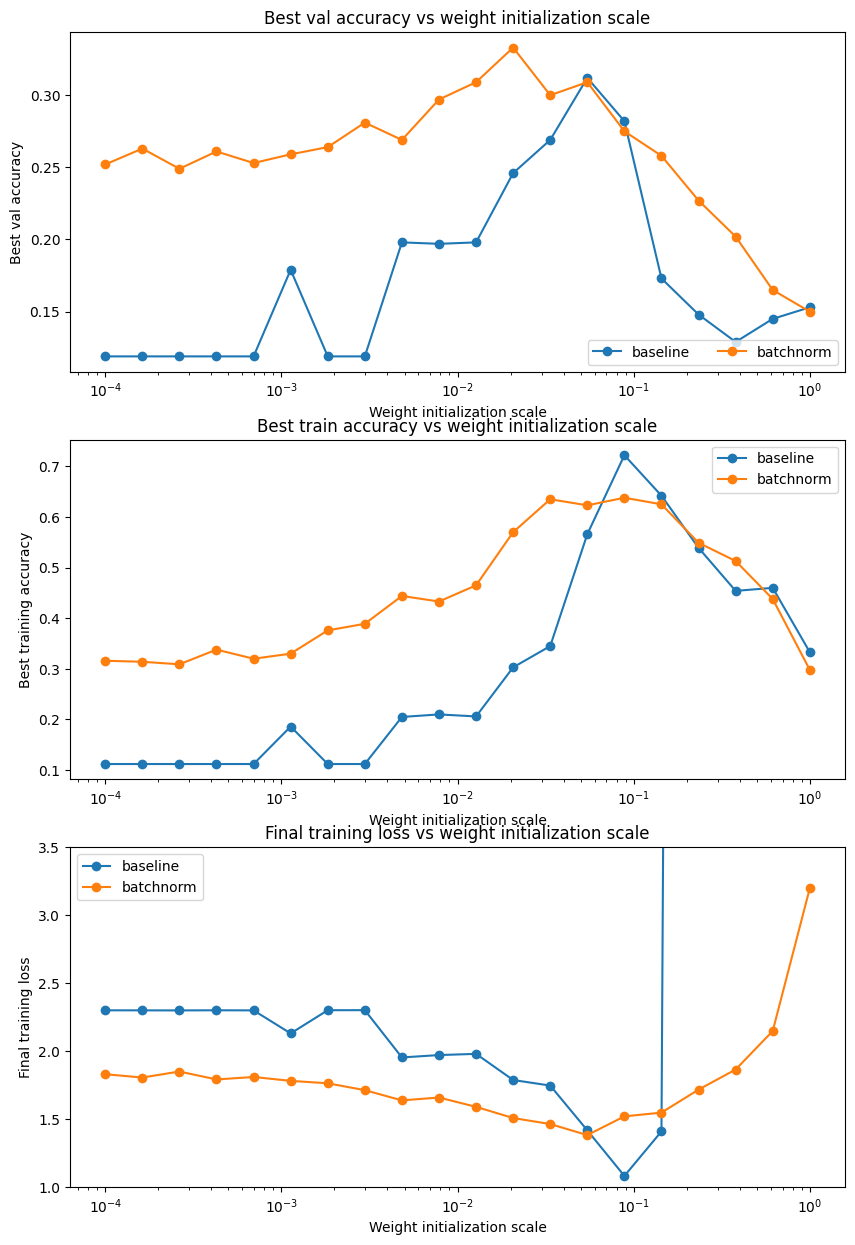

In [12]:
# 重量尺度试验的绘图结果
best_train_accs, bn_best_train_accs = [], []
best_val_accs, bn_best_val_accs = [], []
final_train_loss, bn_final_train_loss = [], []

for ws in weight_scales:
  best_train_accs.append(max(solvers[ws].train_acc_history))
  bn_best_train_accs.append(max(bn_solvers[ws].train_acc_history))
  
  best_val_accs.append(max(solvers[ws].val_acc_history))
  bn_best_val_accs.append(max(bn_solvers[ws].val_acc_history))
  
  final_train_loss.append(np.mean(solvers[ws].loss_history[-100:]))
  bn_final_train_loss.append(np.mean(bn_solvers[ws].loss_history[-100:]))
  
plt.subplot(3, 1, 1)
plt.title('Best val accuracy vs weight initialization scale')
plt.xlabel('Weight initialization scale')
plt.ylabel('Best val accuracy')
plt.semilogx(weight_scales, best_val_accs, '-o', label='baseline')
plt.semilogx(weight_scales, bn_best_val_accs, '-o', label='batchnorm')
plt.legend(ncol=2, loc='lower right')

plt.subplot(3, 1, 2)
plt.title('Best train accuracy vs weight initialization scale')
plt.xlabel('Weight initialization scale')
plt.ylabel('Best training accuracy')
plt.semilogx(weight_scales, best_train_accs, '-o', label='baseline')
plt.semilogx(weight_scales, bn_best_train_accs, '-o', label='batchnorm')
plt.legend()

plt.subplot(3, 1, 3)
plt.title('Final training loss vs weight initialization scale')
plt.xlabel('Weight initialization scale')
plt.ylabel('Final training loss')
plt.semilogx(weight_scales, final_train_loss, '-o', label='baseline')
plt.semilogx(weight_scales, bn_final_train_loss, '-o', label='batchnorm')
plt.legend()
plt.gca().set_ylim(1.0, 3.5)

plt.gcf().set_size_inches(10, 15)
plt.show()

# 问题：
描述一下这个实验的结果，并试着给出一个为什么这个实验得出这样的结果的原因。

# 我的分析

BN 通过批次均值和方差调节中间激活的尺度，并通过 gamma/beta 保留可学习的缩放和平移，因此在初始化尺度扫描中往往拥有更宽的可训练范围。它不意味着任意初始化都安全，也不保证验证准确率一定提高。本次固定 1000 张训练图的对照中，BN 的训练拟合与普通网络不同，但验证结果没有在所有检查点占优；这应与优化稳定性、样本量和正则化共同分析。推理时使用滑动统计，训练与推理分布的差异也会影响结果。

### 保存本次实验
输入是上面实际训练得到的模型、指标和曲线。只保存模型参数与实验结果，不复制原始数据；输出写入本题独立目录，供运行验证核对。

**第 13 块：顺着变量读**

本块实际导入：`study_runtime.save_experiment`。各模块在本题中的职责见开头的库说明。

In [13]:
from study_runtime import save_experiment
experiment_metrics = save_experiment(globals(), '007_BatchNormalization')


本机实验指标： {}


## 实践补充：问题、检查与方法选择

**实际问题。** 极短函数用 time.time 计时可能得到零时间差，导致加速比除零；改为 perf_counter 后重新执行。

**解释边界。** 训练和推理分别使用批次统计与滑动统计，推理不得重新估计验证批次。初始化扫描说明可训练范围，不证明 BN 在任意配置下必然提升验证准确率。

**方法选择。** 简化反向本来就是原题的可选实现，已经做数值和时间对照，不重复登记为本次新增方法二。

更完整的故障证据见 [问题与解决记录](../003_问题与解决记录.md)。